In [2]:
import pandas as pd
import numpy as np

crime_df = pd.read_csv("data/chicago_crime_cleaned.csv")
node_features = pd.read_csv("data/node_features.csv")

print("Crime data:", crime_df.shape)
print("Node features:", node_features.shape)

Crime data: (228595, 17)
Node features: (157, 33)


In [3]:
crime_df["PRIMARY_DESCRIPTION"].value_counts()

PRIMARY_DESCRIPTION
THEFT                                49763
BATTERY                              42093
CRIMINAL DAMAGE                      25501
ASSAULT                              20706
MOTOR VEHICLE THEFT                  18114
OTHER OFFENSE                        15632
DECEPTIVE PRACTICE                   13232
BURGLARY                             12917
NARCOTICS                             6473
CRIMINAL TRESPASS                     5477
WEAPONS VIOLATION                     4901
ROBBERY                               4847
CRIMINAL SEXUAL ASSAULT               1634
OFFENSE INVOLVING CHILDREN            1461
SEX OFFENSE                           1339
PUBLIC PEACE VIOLATION                1110
INTERFERENCE WITH PUBLIC OFFICER       968
STALKING                               631
HOMICIDE                               443
ARSON                                  357
INTIMIDATION                           219
LIQUOR LAW VIOLATION                   195
CONCEALED CARRY LICENSE VIOLATION 

In [4]:
crime_df[
    ["PRIMARY_DESCRIPTION", "SECONDARY_DESCRIPTION"]
].head(20)

,PRIMARY_DESCRIPTION,SECONDARY_DESCRIPTION
0,BATTERY,DOMESTIC BATTERY SIMPLE
1,BATTERY,SIMPLE
2,BURGLARY,UNLAWFUL ENTRY
3,BURGLARY,BURGLARY FROM MOTOR VEHICLE
4,CRIMINAL DAMAGE,TO PROPERTY
5,CRIMINAL DAMAGE,TO VEHICLE
6,BURGLARY,FORCIBLE ENTRY
7,BURGLARY,FORCIBLE ENTRY
8,CRIMINAL DAMAGE,TO VEHICLE
9,THEFT,THEFT FROM MOTOR VEHICLE


In [5]:
import pandas as pd
import numpy as np

crime_df = pd.read_csv("data/chicago_crime_cleaned.csv")

print("Dataset shape:", crime_df.shape)

Dataset shape: (228595, 17)


In [6]:
victimisation_crimes = [
    "ASSAULT",
    "BATTERY",
    "ROBBERY",
    "CRIMINAL SEXUAL ASSAULT",
    "SEX OFFENSE",
    "STALKING",
    "HOMICIDE",
    "KIDNAPPING",
    "OFFENSE INVOLVING CHILDREN",
    "INTIMIDATION",
    "HUMAN TRAFFICKING"
]

print("Victimisation-related crime categories:")
for crime in victimisation_crimes:
    print("-", crime)

Victimisation-related crime categories:
- ASSAULT
- BATTERY
- ROBBERY
- CRIMINAL SEXUAL ASSAULT
- SEX OFFENSE
- STALKING
- HOMICIDE
- KIDNAPPING
- OFFENSE INVOLVING CHILDREN
- INTIMIDATION
- HUMAN TRAFFICKING


In [7]:
crime_df["VICTIMISATION"] = (
    crime_df["PRIMARY_DESCRIPTION"].isin(victimisation_crimes)
).astype(int)

In [8]:
print(crime_df["VICTIMISATION"].value_counts())

VICTIMISATION
0    155101
1     73494
Name: count, dtype: int64


In [9]:
print(
    crime_df["VICTIMISATION"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

VICTIMISATION
0    67.85
1    32.15
Name: proportion, dtype: float64


In [10]:
print("GRID_ID" in crime_df.columns)

False


In [11]:
from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:26916",
    always_xy=True
)

crime_df["X_M"], crime_df["Y_M"] = transformer.transform(
    crime_df["LONGITUDE"].values,
    crime_df["LATITUDE"].values
)

GRID_SIZE = 2200

MIN_X = 425476.99038882746
MIN_Y = 4610479.474780203

crime_df["GRID_ROW"] = np.floor(
    (crime_df["Y_M"] - MIN_Y) / GRID_SIZE
).astype(int)

crime_df["GRID_COL"] = np.floor(
    (crime_df["X_M"] - MIN_X) / GRID_SIZE
).astype(int)

crime_df["GRID_ID"] = (
    crime_df["GRID_ROW"].astype(str)
    + "_"
    + crime_df["GRID_COL"].astype(str)
)

In [12]:
print("GRID_ID" in crime_df.columns)

True


In [13]:
victimisation_by_grid = (
    crime_df.groupby("GRID_ID")
    .agg(
        VICTIMISATION_COUNT=("VICTIMISATION", "sum"),
        TOTAL_CRIME_COUNT=("PRIMARY_DESCRIPTION", "count")
    )
    .reset_index()
)

display(victimisation_by_grid.head())

,GRID_ID,VICTIMISATION_COUNT,TOTAL_CRIME_COUNT
0,0_10,273,595
1,0_11,277,559
2,0_12,40,121
3,0_13,151,451
4,0_9,62,218


In [14]:
victimisation_by_grid["VICTIMISATION_COUNT"].describe()

count     157.000000
mean      468.114650
std       453.773805
min         0.000000
25%        86.000000
50%       320.000000
75%       706.000000
max      2206.000000
Name: VICTIMISATION_COUNT, dtype: float64

In [15]:
RISK_PERCENTILE = 80

risk_threshold = np.percentile(
    victimisation_by_grid["VICTIMISATION_COUNT"],
    RISK_PERCENTILE
)

print("Risk threshold:", risk_threshold)

Risk threshold: 836.2000000000002


In [16]:
victimisation_by_grid["HIGH_VICTIMISATION_RISK"] = (
    victimisation_by_grid["VICTIMISATION_COUNT"]
    >= risk_threshold
).astype(int)

In [17]:
print(
    victimisation_by_grid[
        "HIGH_VICTIMISATION_RISK"
    ].value_counts()
)

HIGH_VICTIMISATION_RISK
0    125
1     32
Name: count, dtype: int64


In [18]:
print(
    victimisation_by_grid[
        "HIGH_VICTIMISATION_RISK"
    ]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

HIGH_VICTIMISATION_RISK
0    79.62
1    20.38
Name: proportion, dtype: float64


In [19]:
top_risk_areas = victimisation_by_grid.sort_values(
    "VICTIMISATION_COUNT",
    ascending=False
)

display(top_risk_areas.head(20))

,GRID_ID,VICTIMISATION_COUNT,TOTAL_CRIME_COUNT,HIGH_VICTIMISATION_RISK
17,12_10,2206,9549,1
124,6_10,1890,4464,1
13,11_6,1840,4868,1
117,5_12,1524,3960,1
14,11_7,1465,3967,1
20,12_5,1450,3621,1
116,5_11,1434,3606,1
123,5_9,1424,3651,1
133,6_9,1314,3184,1
115,5_10,1312,3637,1


In [20]:
import pandas as pd
import numpy as np

from pyproj import Transformer

crime_df = pd.read_csv(
    "data/chicago_crime_cleaned.csv"
)

crime_df["DATE_OF_OCCURRENCE"] = pd.to_datetime(
    crime_df["DATE_OF_OCCURRENCE"],
    errors="coerce"
)

print("Shape:", crime_df.shape)
print(
    "Date range:",
    crime_df["DATE_OF_OCCURRENCE"].min(),
    "to",
    crime_df["DATE_OF_OCCURRENCE"].max()
)

Shape: (228595, 17)
Date range: 2025-08-24 05:03:00 to 2026-08-23 00:00:00


In [21]:
victimisation_crimes = [
    "ASSAULT",
    "BATTERY",
    "ROBBERY",
    "CRIMINAL SEXUAL ASSAULT",
    "SEX OFFENSE",
    "STALKING",
    "HOMICIDE",
    "KIDNAPPING",
    "OFFENSE INVOLVING CHILDREN",
    "INTIMIDATION",
    "HUMAN TRAFFICKING"
]

crime_df["VICTIMISATION"] = (
    crime_df["PRIMARY_DESCRIPTION"]
    .isin(victimisation_crimes)
).astype(int)

print(
    crime_df["VICTIMISATION"].value_counts()
)

VICTIMISATION
0    155101
1     73494
Name: count, dtype: int64


In [22]:
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:26916",
    always_xy=True
)

crime_df["X_M"], crime_df["Y_M"] = transformer.transform(
    crime_df["LONGITUDE"].values,
    crime_df["LATITUDE"].values
)

GRID_SIZE = 2200

MIN_X = 425476.99038882746
MIN_Y = 4610479.474780203

crime_df["GRID_ROW"] = np.floor(
    (crime_df["Y_M"] - MIN_Y) / GRID_SIZE
).astype(int)

crime_df["GRID_COL"] = np.floor(
    (crime_df["X_M"] - MIN_X) / GRID_SIZE
).astype(int)

crime_df["GRID_ID"] = (
    crime_df["GRID_ROW"].astype(str)
    + "_"
    + crime_df["GRID_COL"].astype(str)
)

print(
    "Unique grid cells:",
    crime_df["GRID_ID"].nunique()
)

Unique grid cells: 157


In [23]:
crime_df["DATE"] = (
    crime_df["DATE_OF_OCCURRENCE"]
    .dt.normalize()
)

daily_features = (
    crime_df
    .groupby(["DATE", "GRID_ID"])
    .agg(
        TOTAL_CRIME=("PRIMARY_DESCRIPTION", "count"),
        VICTIMISATION_COUNT=("VICTIMISATION", "sum"),
        DOMESTIC_COUNT=("DOMESTIC", "sum"),
        ARREST_COUNT=("ARREST", "sum"),
        UNIQUE_CRIME_TYPES=("PRIMARY_DESCRIPTION", "nunique"),
        UNIQUE_LOCATIONS=("LOCATION_DESCRIPTION", "nunique")
    )
    .reset_index()
)

display(daily_features.head())

,DATE,GRID_ID,TOTAL_CRIME,VICTIMISATION_COUNT,DOMESTIC_COUNT,ARREST_COUNT,UNIQUE_CRIME_TYPES,UNIQUE_LOCATIONS
0,2025-08-24,0_10,1,0,N,N,1,1
1,2025-08-24,0_13,1,1,N,N,1,1
2,2025-08-24,10_10,6,1,NNYNNN,NNYNNN,5,5
3,2025-08-24,10_6,8,4,NNNYNNNN,NNNNNNYN,6,7
4,2025-08-24,10_7,9,5,YNNNYNYNN,YNNYNNNNN,4,8


In [24]:
daily_features["VICTIMISATION_RATE"] = (
    daily_features["VICTIMISATION_COUNT"]
    / daily_features["TOTAL_CRIME"]
).fillna(0)

In [25]:
all_dates = sorted(
    crime_df["DATE"].dropna().unique()
)

n_dates = len(all_dates)

cutoff_index = int(n_dates * 0.80)

cutoff_date = all_dates[cutoff_index]

print("Number of dates:", n_dates)
print("Cutoff date:", cutoff_date)

Number of dates: 365
Cutoff date: 2026-06-12 00:00:00


In [26]:
history_df = crime_df[
    crime_df["DATE"] < cutoff_date
].copy()

future_df = crime_df[
    crime_df["DATE"] >= cutoff_date
].copy()

print("Historical records:", len(history_df))
print("Future records:", len(future_df))

Historical records: 182058
Future records: 46537


In [27]:
historical_features = (
    history_df
    .groupby("GRID_ID")
    .agg(
        HIST_TOTAL_CRIME=(
            "PRIMARY_DESCRIPTION",
            "count"
        ),

        HIST_VICTIMISATION=(
            "VICTIMISATION",
            "sum"
        ),

        HIST_DOMESTIC=(
            "DOMESTIC",
            "sum"
        ),

        HIST_ARREST=(
            "ARREST",
            "sum"
        ),

        HIST_UNIQUE_CRIMES=(
            "PRIMARY_DESCRIPTION",
            "nunique"
        ),

        HIST_UNIQUE_LOCATIONS=(
            "LOCATION_DESCRIPTION",
            "nunique"
        )
    )
    .reset_index()
)

display(historical_features.head())

,GRID_ID,HIST_TOTAL_CRIME,HIST_VICTIMISATION,HIST_DOMESTIC,HIST_ARREST,HIST_UNIQUE_CRIMES,HIST_UNIQUE_LOCATIONS
0,0_10,458,213,NNYNYNNNNYNNYYNNNNNNYNNNNYYNNNNNYNNNYNYYYNNNYN...,NNNYNNNYYNYNNNNNNNNNNNNNNNNNNNNNNNYNYNNNNNNNNN...,19,21
1,0_11,431,209,YYNNNNNNYNNNYYNNYYYNNYNNNNYNNNNNNNNNNNYNNNNYNN...,NNNNNNNYNNNYNYYNNNNNYNYNNNYNNNNNNNNNNNNNNNNNNN...,16,22
2,0_12,102,34,NNYNNNNNNYNNNNNYNYYNYNNNNNNYNNNNNNNNNNNNYNYYNN...,NNNNNNNNNNYNNNNNNNNNNNNNYNYNNNNNNNNNNNNNNNNNYN...,13,17
3,0_13,341,117,NNNNNNNNNNYYNNYNNNNNNYYNNYNYNNNNNYNNNYYNNNNNNN...,NNNNNNNNNNNNNNYNNNNYNNNNNNNNNNNNNNNNNNYYNNNNNN...,16,28
4,0_9,169,46,NYNNNYNNNNNNNNNNNNNYYNNYNNNYNYNYNNNNNYNNNNNNNN...,NNNNYNNNYNNNNYNNNNNNYNNNNNNNNNNNNNNNYNNYNNNNNN...,18,18


In [28]:
historical_features["HIST_VICTIMISATION_RATE"] = (
    historical_features["HIST_VICTIMISATION"]
    / historical_features["HIST_TOTAL_CRIME"]
).fillna(0)

In [29]:
crime_type_history = (
    history_df
    .groupby(["GRID_ID", "PRIMARY_DESCRIPTION"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

crime_type_history.head()

PRIMARY_DESCRIPTION,GRID_ID,ARSON,ASSAULT,BATTERY,BURGLARY,CONCEALED CARRY LICENSE VIOLATION,CRIMINAL DAMAGE,CRIMINAL SEXUAL ASSAULT,CRIMINAL TRESPASS,DECEPTIVE PRACTICE,...,OTHER NARCOTIC VIOLATION,OTHER OFFENSE,PROSTITUTION,PUBLIC INDECENCY,PUBLIC PEACE VIOLATION,ROBBERY,SEX OFFENSE,STALKING,THEFT,WEAPONS VIOLATION
0,0_10,1,65,121,20,0,56,4,6,13,...,0,47,0,0,0,15,2,0,45,24
1,0_11,0,72,117,8,0,55,3,7,7,...,0,51,0,0,0,9,0,0,46,17
2,0_12,0,8,22,5,0,18,1,4,1,...,0,9,0,0,1,3,0,0,13,0
3,0_13,0,35,68,17,0,78,2,9,14,...,0,30,0,0,1,4,5,2,30,4
4,0_9,0,11,27,10,0,21,1,4,6,...,0,19,0,0,1,2,2,2,31,3


In [30]:
crime_type_columns = [
    col for col in crime_type_history.columns
    if col != "GRID_ID"
]

crime_type_history = crime_type_history.rename(
    columns={
        col: "HIST_" + col.replace(" ", "_")
        for col in crime_type_columns
    }
)

display(crime_type_history.head())

PRIMARY_DESCRIPTION,GRID_ID,HIST_ARSON,HIST_ASSAULT,HIST_BATTERY,HIST_BURGLARY,HIST_CONCEALED_CARRY_LICENSE_VIOLATION,HIST_CRIMINAL_DAMAGE,HIST_CRIMINAL_SEXUAL_ASSAULT,HIST_CRIMINAL_TRESPASS,HIST_DECEPTIVE_PRACTICE,...,HIST_OTHER_NARCOTIC_VIOLATION,HIST_OTHER_OFFENSE,HIST_PROSTITUTION,HIST_PUBLIC_INDECENCY,HIST_PUBLIC_PEACE_VIOLATION,HIST_ROBBERY,HIST_SEX_OFFENSE,HIST_STALKING,HIST_THEFT,HIST_WEAPONS_VIOLATION
0,0_10,1,65,121,20,0,56,4,6,13,...,0,47,0,0,0,15,2,0,45,24
1,0_11,0,72,117,8,0,55,3,7,7,...,0,51,0,0,0,9,0,0,46,17
2,0_12,0,8,22,5,0,18,1,4,1,...,0,9,0,0,1,3,0,0,13,0
3,0_13,0,35,68,17,0,78,2,9,14,...,0,30,0,0,1,4,5,2,30,4
4,0_9,0,11,27,10,0,21,1,4,6,...,0,19,0,0,1,2,2,2,31,3


In [31]:
phase2_features = historical_features.merge(
    crime_type_history,
    on="GRID_ID",
    how="left"
)

print("Phase 2 feature shape:")
print(phase2_features.shape)

display(phase2_features.head())

Phase 2 feature shape:
(153, 39)


,GRID_ID,HIST_TOTAL_CRIME,HIST_VICTIMISATION,HIST_DOMESTIC,HIST_ARREST,HIST_UNIQUE_CRIMES,HIST_UNIQUE_LOCATIONS,HIST_VICTIMISATION_RATE,HIST_ARSON,HIST_ASSAULT,...,HIST_OTHER_NARCOTIC_VIOLATION,HIST_OTHER_OFFENSE,HIST_PROSTITUTION,HIST_PUBLIC_INDECENCY,HIST_PUBLIC_PEACE_VIOLATION,HIST_ROBBERY,HIST_SEX_OFFENSE,HIST_STALKING,HIST_THEFT,HIST_WEAPONS_VIOLATION
0,0_10,458,213,NNYNYNNNNYNNYYNNNNNNYNNNNYYNNNNNYNNNYNYYYNNNYN...,NNNYNNNYYNYNNNNNNNNNNNNNNNNNNNNNNNYNYNNNNNNNNN...,19,21,0.465066,1,65,...,0,47,0,0,0,15,2,0,45,24
1,0_11,431,209,YYNNNNNNYNNNYYNNYYYNNYNNNNYNNNNNNNNNNNYNNNNYNN...,NNNNNNNYNNNYNYYNNNNNYNYNNNYNNNNNNNNNNNNNNNNNNN...,16,22,0.484919,0,72,...,0,51,0,0,0,9,0,0,46,17
2,0_12,102,34,NNYNNNNNNYNNNNNYNYYNYNNNNNNYNNNNNNNNNNNNYNYYNN...,NNNNNNNNNNYNNNNNNNNNNNNNYNYNNNNNNNNNNNNNNNNNYN...,13,17,0.333333,0,8,...,0,9,0,0,1,3,0,0,13,0
3,0_13,341,117,NNNNNNNNNNYYNNYNNNNNNYYNNYNYNNNNNYNNNYYNNNNNNN...,NNNNNNNNNNNNNNYNNNNYNNNNNNNNNNNNNNNNNNYYNNNNNN...,16,28,0.343109,0,35,...,0,30,0,0,1,4,5,2,30,4
4,0_9,169,46,NYNNNYNNNNNNNNNNNNNYYNNYNNNYNYNYNNNNNYNNNNNNNN...,NNNNYNNNYNNNNYNNNNNNYNNNNNNNNNNNNNNNYNNYNNNNNN...,18,18,0.272189,0,11,...,0,19,0,0,1,2,2,2,31,3


In [32]:
future_target = (
    future_df
    .groupby("GRID_ID")
    .agg(
        FUTURE_VICTIMISATION=(
            "VICTIMISATION",
            "sum"
        ),
        FUTURE_TOTAL_CRIME=(
            "PRIMARY_DESCRIPTION",
            "count"
        )
    )
    .reset_index()
)

display(future_target.head())

,GRID_ID,FUTURE_VICTIMISATION,FUTURE_TOTAL_CRIME
0,0_10,60,137
1,0_11,68,128
2,0_12,6,19
3,0_13,34,110
4,0_9,16,49


In [33]:
phase2_dataset = phase2_features.merge(
    future_target,
    on="GRID_ID",
    how="left"
)

phase2_dataset[
    [
        "FUTURE_VICTIMISATION",
        "FUTURE_TOTAL_CRIME"
    ]
] = phase2_dataset[
    [
        "FUTURE_VICTIMISATION",
        "FUTURE_TOTAL_CRIME"
    ]
].fillna(0)

print(
    "Final Phase 2 dataset:",
    phase2_dataset.shape
)

Final Phase 2 dataset: (153, 41)


In [34]:
risk_threshold = np.percentile(
    phase2_dataset["HIST_VICTIMISATION"],
    80
)

print(
    "Historical victimisation threshold:",
    risk_threshold
)

Historical victimisation threshold: 664.2


In [35]:
phase2_dataset["HIGH_VICTIMISATION_RISK"] = (
    phase2_dataset["FUTURE_VICTIMISATION"]
    >= risk_threshold
).astype(int)

In [36]:
print(
    phase2_dataset[
        "HIGH_VICTIMISATION_RISK"
    ].value_counts()
)

print("\nPercentage:")
print(
    phase2_dataset[
        "HIGH_VICTIMISATION_RISK"
    ]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

HIGH_VICTIMISATION_RISK
0    153
Name: count, dtype: int64

Percentage:
HIGH_VICTIMISATION_RISK
0    100.0
Name: proportion, dtype: float64


In [37]:
phase2_dataset.to_csv(
    "data/phase2_victimisation_dataset.csv",
    index=False
)

print(
    "Saved: data/phase2_victimisation_dataset.csv"
)

Saved: data/phase2_victimisation_dataset.csv


In [38]:
print("Cutoff:", cutoff_date)
print("Phase 2 shape:", phase2_dataset.shape)
print("Risk threshold:", risk_threshold)
print(phase2_dataset["HIGH_VICTIMISATION_RISK"].value_counts())

Cutoff: 2026-06-12 00:00:00
Phase 2 shape: (153, 42)
Risk threshold: 664.2
HIGH_VICTIMISATION_RISK
0    153
Name: count, dtype: int64


In [39]:
# Calculate the number of days in each period

historical_start = history_df["DATE"].min()
historical_end = history_df["DATE"].max()

future_start = future_df["DATE"].min()
future_end = future_df["DATE"].max()

historical_days = (
    historical_end - historical_start
).days + 1

future_days = (
    future_end - future_start
).days + 1

print("Historical period:")
print(historical_start, "to", historical_end)
print("Number of days:", historical_days)

print("\nFuture period:")
print(future_start, "to", future_end)
print("Number of days:", future_days)

Historical period:
2025-08-24 00:00:00 to 2026-06-11 00:00:00
Number of days: 292

Future period:
2026-06-12 00:00:00 to 2026-08-23 00:00:00
Number of days: 73


In [40]:
phase2_dataset["HIST_VICTIMISATION_PER_DAY"] = (
    phase2_dataset["HIST_VICTIMISATION"]
    / historical_days
)

phase2_dataset["FUTURE_VICTIMISATION_PER_DAY"] = (
    phase2_dataset["FUTURE_VICTIMISATION"]
    / future_days
)

display(
    phase2_dataset[
        [
            "GRID_ID",
            "HIST_VICTIMISATION",
            "HIST_VICTIMISATION_PER_DAY",
            "FUTURE_VICTIMISATION",
            "FUTURE_VICTIMISATION_PER_DAY"
        ]
    ].head(10)
)

,GRID_ID,HIST_VICTIMISATION,HIST_VICTIMISATION_PER_DAY,FUTURE_VICTIMISATION,FUTURE_VICTIMISATION_PER_DAY
0,0_10,213,0.729452,60.0,0.821918
1,0_11,209,0.715753,68.0,0.931507
2,0_12,34,0.116438,6.0,0.082192
3,0_13,117,0.400685,34.0,0.465753
4,0_9,46,0.157534,16.0,0.219178
5,10_10,510,1.746575,129.0,1.767123
6,10_6,900,3.082192,235.0,3.219178
7,10_7,873,2.989726,204.0,2.794521
8,10_8,433,1.482877,109.0,1.493151
9,10_9,444,1.520548,117.0,1.602740


In [41]:
risk_threshold = np.percentile(
    phase2_dataset["HIST_VICTIMISATION_PER_DAY"],
    80
)

print(
    "Historical daily victimisation risk threshold:",
    round(risk_threshold, 4)
)

Historical daily victimisation risk threshold: 2.2747


In [42]:
grid_nodes = pd.read_csv("data/chicago_spatial_grid.csv")

print("Grid nodes:", len(grid_nodes))
print("Current Phase 2 rows:", len(phase2_dataset))

Grid nodes: 157
Current Phase 2 rows: 153


In [43]:
phase2_dataset = grid_nodes[
    [
        "GRID_ID",
        "GRID_ROW",
        "GRID_COL",
        "GRID_CENTER_LAT",
        "GRID_CENTER_LON"
    ]
].merge(
    phase2_dataset,
    on="GRID_ID",
    how="left"
)

print("After adding all grid cells:", phase2_dataset.shape)

After adding all grid cells: (157, 48)


In [44]:
numeric_columns = phase2_dataset.select_dtypes(
    include=[np.number]
).columns

phase2_dataset[numeric_columns] = (
    phase2_dataset[numeric_columns].fillna(0)
)

print("Missing values after filling:")
print(phase2_dataset.isna().sum().sum())

Missing values after filling:
8


In [45]:
missing = phase2_dataset.isna().sum()

print("Columns with missing values:")
print(missing[missing > 0])

Columns with missing values:
HIST_DOMESTIC    4
HIST_ARREST      4
dtype: int64


In [46]:
missing_rows = phase2_dataset[
    phase2_dataset.isna().any(axis=1)
]

print("Number of rows with missing values:",
      len(missing_rows))

display(missing_rows)

Number of rows with missing values: 4


,GRID_ID,GRID_ROW,GRID_COL,GRID_CENTER_LAT,GRID_CENTER_LON,HIST_TOTAL_CRIME,HIST_VICTIMISATION,HIST_DOMESTIC,HIST_ARREST,HIST_UNIQUE_CRIMES,...,HIST_ROBBERY,HIST_SEX_OFFENSE,HIST_STALKING,HIST_THEFT,HIST_WEAPONS_VIOLATION,FUTURE_VICTIMISATION,FUTURE_TOTAL_CRIME,HIGH_VICTIMISATION_RISK,HIST_VICTIMISATION_PER_DAY,FUTURE_VICTIMISATION_PER_DAY
5,1_6,1,6,41.673503,-87.723487,0.0,0.0,NaN,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30,3_14,3,14,41.714269,-87.512375,0.0,0.0,NaN,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
139,17_1,17,1,41.989604,-87.859855,0.0,0.0,NaN,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
148,18_0,18,0,42.009214,-87.886687,0.0,0.0,NaN,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [47]:
phase2_dataset["HIST_DOMESTIC"] = (
    phase2_dataset["HIST_DOMESTIC"].fillna(0)
)

phase2_dataset["HIST_ARREST"] = (
    phase2_dataset["HIST_ARREST"].fillna(0)
)

print("Missing values after correction:")
print(phase2_dataset.isna().sum().sum())

Missing values after correction:
0


In [48]:
empty_historical_cells = phase2_dataset[
    phase2_dataset["HIST_TOTAL_CRIME"] == 0
]

display(
    empty_historical_cells[
        [
            "GRID_ID",
            "HIST_TOTAL_CRIME",
            "HIST_VICTIMISATION",
            "HIST_DOMESTIC",
            "HIST_ARREST"
        ]
    ]
)

,GRID_ID,HIST_TOTAL_CRIME,HIST_VICTIMISATION,HIST_DOMESTIC,HIST_ARREST
5,1_6,0.0,0.0,0,0
30,3_14,0.0,0.0,0,0
139,17_1,0.0,0.0,0,0
148,18_0,0.0,0.0,0,0


In [49]:
print("Dataset shape:", phase2_dataset.shape)

print("\nTarget distribution:")
print(
    phase2_dataset["HIGH_VICTIMISATION_RISK"].value_counts()
)

print("\nTarget percentages:")
print(
    phase2_dataset["HIGH_VICTIMISATION_RISK"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Dataset shape: (157, 48)

Target distribution:
HIGH_VICTIMISATION_RISK
0.0    157
Name: count, dtype: int64

Target percentages:
HIGH_VICTIMISATION_RISK
0.0    100.0
Name: proportion, dtype: float64


In [50]:
phase2_dataset.to_csv(
    "data/phase2_victimisation_dataset.csv",
    index=False
)

print("Saved:")
print("data/phase2_victimisation_dataset.csv")

Saved:
data/phase2_victimisation_dataset.csv


In [51]:
print("Future victimisation per day statistics:")
print(
    phase2_dataset["FUTURE_VICTIMISATION_PER_DAY"].describe()
)

Future victimisation per day statistics:
count    157.000000
mean       1.356513
std        1.338524
min        0.000000
25%        0.232877
50%        0.945205
75%        2.054795
max        6.424658
Name: FUTURE_VICTIMISATION_PER_DAY, dtype: float64


In [52]:
print("\nFuture victimisation per day percentiles:")
print(
    phase2_dataset["FUTURE_VICTIMISATION_PER_DAY"]
    .quantile([0.25, 0.50, 0.75, 0.80, 0.90, 0.95])
)


Future victimisation per day percentiles:
0.25    0.232877
0.50    0.945205
0.75    2.054795
0.80    2.457534
0.90    3.347945
0.95    3.887671
Name: FUTURE_VICTIMISATION_PER_DAY, dtype: float64


In [53]:
future_risk_threshold = np.percentile(
    phase2_dataset["FUTURE_VICTIMISATION_PER_DAY"],
    80
)

print("Future victimisation risk threshold:", future_risk_threshold)

Future victimisation risk threshold: 2.457534246575343


In [54]:
phase2_dataset["HIGH_VICTIMISATION_RISK"] = (
    phase2_dataset["FUTURE_VICTIMISATION_PER_DAY"]
    >= future_risk_threshold
).astype(int)

In [55]:
print("Target distribution:")
print(
    phase2_dataset["HIGH_VICTIMISATION_RISK"]
    .value_counts()
    .sort_index()
)

print("\nTarget percentages:")
print(
    phase2_dataset["HIGH_VICTIMISATION_RISK"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Target distribution:
HIGH_VICTIMISATION_RISK
0    125
1     32
Name: count, dtype: int64

Target percentages:
HIGH_VICTIMISATION_RISK
0    79.62
1    20.38
Name: proportion, dtype: float64


In [56]:
high_risk_cells = phase2_dataset[
    phase2_dataset["HIGH_VICTIMISATION_RISK"] == 1
].sort_values(
    "FUTURE_VICTIMISATION_PER_DAY",
    ascending=False
)

display(
    high_risk_cells[
        [
            "GRID_ID",
            "GRID_CENTER_LAT",
            "GRID_CENTER_LON",
            "HIST_VICTIMISATION_PER_DAY",
            "FUTURE_VICTIMISATION_PER_DAY",
            "HIGH_VICTIMISATION_RISK"
        ]
    ].head(20)
)

,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,HIST_VICTIMISATION_PER_DAY,FUTURE_VICTIMISATION_PER_DAY,HIGH_VICTIMISATION_RISK
100,12_10,41.892077,-87.619871,5.948630,6.424658,1
89,11_6,41.871642,-87.725717,4.969178,5.328767,1
56,6_10,41.773192,-87.618725,5.188356,5.136986,1
95,12_5,41.891284,-87.752459,3.760274,4.821918,1
47,5_12,41.753650,-87.565613,4.017123,4.808219,1
44,5_9,41.753232,-87.644996,3.750000,4.506849,1
90,11_7,41.871806,-87.699208,4.006849,4.041096,1
55,6_9,41.773047,-87.645194,3.503425,3.986301,1
88,11_5,41.871471,-87.752226,3.160959,3.863014,1
93,11_10,41.872263,-87.619680,3.273973,3.835616,1


In [57]:
future_columns = [
    "FUTURE_VICTIMISATION",
    "FUTURE_TOTAL_CRIME",
    "FUTURE_VICTIMISATION_PER_DAY",
    "HIGH_VICTIMISATION_RISK"
]

In [58]:
phase2_dataset.to_csv(
    "data/phase2_victimisation_dataset.csv",
    index=False
)

print("Phase 2 dataset saved successfully.")
print("Shape:", phase2_dataset.shape)

Phase 2 dataset saved successfully.
Shape: (157, 48)


In [59]:
# Historical features only
phase2_feature_columns = [
    "GRID_CENTER_LAT",
    "GRID_CENTER_LON",
    "HIST_TOTAL_CRIME",
    "HIST_VICTIMISATION",
    "HIST_DOMESTIC",
    "HIST_ARREST",
    "HIST_UNIQUE_CRIMES",
    "HIST_UNIQUE_LOCATIONS",
    "HIST_VICTIMISATION_RATE",
    "HIST_VICTIMISATION_PER_DAY"
]

print("Number of features:", len(phase2_feature_columns))
print("\nFeatures:")
for feature in phase2_feature_columns:
    print("-", feature)

Number of features: 10

Features:
- GRID_CENTER_LAT
- GRID_CENTER_LON
- HIST_TOTAL_CRIME
- HIST_VICTIMISATION
- HIST_DOMESTIC
- HIST_ARREST
- HIST_UNIQUE_CRIMES
- HIST_UNIQUE_LOCATIONS
- HIST_VICTIMISATION_RATE
- HIST_VICTIMISATION_PER_DAY


In [60]:
X_phase2 = phase2_dataset[phase2_feature_columns].copy()

y_phase2 = phase2_dataset["HIGH_VICTIMISATION_RISK"].astype(int)

print("X shape:", X_phase2.shape)
print("y shape:", y_phase2.shape)

X shape: (157, 10)
y shape: (157,)


In [61]:
print("Missing values:", X_phase2.isna().sum().sum())
print("Infinite values:", np.isinf(X_phase2.select_dtypes(include=np.number)).sum().sum())

Missing values: 0
Infinite values: 0


In [62]:
display(X_phase2.describe().T)

,count,mean,std,min,25%,50%,75%,max
GRID_CENTER_LAT,157.0,41.837514,0.110035,41.654160,41.733963,41.832337,41.931558,42.030472
GRID_CENTER_LON,157.0,-87.687781,0.084812,-87.886687,-87.751068,-87.674158,-87.619871,-87.512217
HIST_TOTAL_CRIME,157.0,1159.605096,1122.482618,0.000000,222.000000,882.000000,1859.000000,7678.000000
HIST_VICTIMISATION,157.0,369.070064,357.021441,0.000000,69.000000,260.000000,558.000000,1737.000000
HIST_UNIQUE_CRIMES,157.0,18.891720,6.234293,0.000000,16.000000,21.000000,23.000000,27.000000
HIST_UNIQUE_LOCATIONS,157.0,38.273885,18.415299,0.000000,25.000000,41.000000,53.000000,79.000000
HIST_VICTIMISATION_RATE,157.0,0.303369,0.096999,0.000000,0.260791,0.315789,0.361111,0.600000
HIST_VICTIMISATION_PER_DAY,157.0,1.263939,1.222676,0.000000,0.236301,0.890411,1.910959,5.948630


In [63]:
print("Target classes:")
print(y_phase2.value_counts().sort_index())

Target classes:
HIGH_VICTIMISATION_RISK
0    125
1     32
Name: count, dtype: int64


In [64]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X_phase2,
    y_phase2,
    test_size=0.30,
    stratify=y_phase2,
    random_state=42
)

print("Training set:", X_train.shape)
print("Temporary set:", X_temp.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

Training set: (109, 10)
Temporary set: (48, 10)

Training target distribution:
HIGH_VICTIMISATION_RISK
0    87
1    22
Name: count, dtype: int64


In [65]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (109, 10)
Validation: (24, 10)
Test: (24, 10)


In [66]:
print("TRAIN")
print(y_train.value_counts().sort_index())
print(
    y_train.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nVALIDATION")
print(y_val.value_counts().sort_index())
print(
    y_val.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nTEST")
print(y_test.value_counts().sort_index())
print(
    y_test.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

TRAIN
HIGH_VICTIMISATION_RISK
0    87
1    22
Name: count, dtype: int64
HIGH_VICTIMISATION_RISK
0    79.82
1    20.18
Name: proportion, dtype: float64

VALIDATION
HIGH_VICTIMISATION_RISK
0    19
1     5
Name: count, dtype: int64
HIGH_VICTIMISATION_RISK
0    79.17
1    20.83
Name: proportion, dtype: float64

TEST
HIGH_VICTIMISATION_RISK
0    19
1     5
Name: count, dtype: int64
HIGH_VICTIMISATION_RISK
0    79.17
1    20.83
Name: proportion, dtype: float64


In [67]:
print(X_phase2.dtypes)

GRID_CENTER_LAT               float64
GRID_CENTER_LON               float64
HIST_TOTAL_CRIME              float64
HIST_VICTIMISATION            float64
HIST_DOMESTIC                  object
HIST_ARREST                    object
HIST_UNIQUE_CRIMES            float64
HIST_UNIQUE_LOCATIONS         float64
HIST_VICTIMISATION_RATE       float64
HIST_VICTIMISATION_PER_DAY    float64
dtype: object


In [68]:
print("crime_df shape:", crime_df.shape)
print("\ncrime_df columns:")
print(crime_df.columns.tolist())

crime_df shape: (228595, 24)

crime_df columns:
['CASE#', 'DATE_OF_OCCURRENCE', 'BLOCK', 'IUCR', 'PRIMARY_DESCRIPTION', 'SECONDARY_DESCRIPTION', 'LOCATION_DESCRIPTION', 'ARREST', 'DOMESTIC', 'BEAT', 'WARD', 'FBI_CD', 'X_COORDINATE', 'Y_COORDINATE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'VICTIMISATION', 'X_M', 'Y_M', 'GRID_ROW', 'GRID_COL', 'GRID_ID', 'DATE']


In [69]:
crime_df["ARREST_FLAG"] = (
    crime_df["ARREST"]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("Y")
    .astype(int)
)

crime_df["DOMESTIC_FLAG"] = (
    crime_df["DOMESTIC"]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("Y")
    .astype(int)
)

In [70]:
print("ARREST_FLAG:")
print(crime_df["ARREST_FLAG"].value_counts(dropna=False))

print("\nDOMESTIC_FLAG:")
print(crime_df["DOMESTIC_FLAG"].value_counts(dropna=False))

ARREST_FLAG:
ARREST_FLAG
0    193248
1     35347
Name: count, dtype: int64

DOMESTIC_FLAG:
DOMESTIC_FLAG
0    184611
1     43984
Name: count, dtype: int64


In [71]:
cutoff_date = pd.Timestamp("2026-06-12 00:00:00")

history_df = crime_df[
    crime_df["DATE_OF_OCCURRENCE"] < cutoff_date
].copy()

In [72]:
print("Historical dataset shape:", history_df.shape)
print(
    "Historical date range:",
    history_df["DATE_OF_OCCURRENCE"].min(),
    "to",
    history_df["DATE_OF_OCCURRENCE"].max()
)

Historical dataset shape: (182058, 26)
Historical date range: 2025-08-24 05:03:00 to 2026-06-11 23:59:00


In [73]:
required_columns = [
    "GRID_ID",
    "PRIMARY_DESCRIPTION",
    "LOCATION_DESCRIPTION",
    "VICTIMISATION",
    "ARREST_FLAG",
    "DOMESTIC_FLAG"
]

missing_columns = [
    col for col in required_columns
    if col not in history_df.columns
]

print("Missing required columns:", missing_columns)

Missing required columns: []


In [74]:
historical_features = (
    history_df
    .groupby("GRID_ID")
    .agg(
        HIST_TOTAL_CRIME=("PRIMARY_DESCRIPTION", "count"),
        HIST_VICTIMISATION=("VICTIMISATION", "sum"),
        HIST_DOMESTIC=("DOMESTIC_FLAG", "sum"),
        HIST_ARREST=("ARREST_FLAG", "sum"),
        HIST_UNIQUE_CRIMES=("PRIMARY_DESCRIPTION", "nunique"),
        HIST_UNIQUE_LOCATIONS=("LOCATION_DESCRIPTION", "nunique")
    )
    .reset_index()
)

In [75]:
historical_features["HIST_VICTIMISATION_RATE"] = (
    historical_features["HIST_VICTIMISATION"]
    / historical_features["HIST_TOTAL_CRIME"]
).fillna(0)

historical_features["HIST_VICTIMISATION_PER_DAY"] = (
    historical_features["HIST_VICTIMISATION"]
    / historical_days
)

In [76]:
print("Historical features shape:", historical_features.shape)
display(historical_features.head())

Historical features shape: (153, 9)


,GRID_ID,HIST_TOTAL_CRIME,HIST_VICTIMISATION,HIST_DOMESTIC,HIST_ARREST,HIST_UNIQUE_CRIMES,HIST_UNIQUE_LOCATIONS,HIST_VICTIMISATION_RATE,HIST_VICTIMISATION_PER_DAY
0,0_10,458,213,177,60,19,21,0.465066,0.729452
1,0_11,431,209,152,72,16,22,0.484919,0.715753
2,0_12,102,34,23,7,13,17,0.333333,0.116438
3,0_13,341,117,80,29,16,28,0.343109,0.400685
4,0_9,169,46,50,20,18,18,0.272189,0.157534


In [77]:
phase2_dataset = grid_nodes[
    [
        "GRID_ID",
        "GRID_ROW",
        "GRID_COL",
        "GRID_CENTER_LAT",
        "GRID_CENTER_LON"
    ]
].merge(
    historical_features,
    on="GRID_ID",
    how="left"
).merge(
    future_target,
    on="GRID_ID",
    how="left"
)

In [78]:
count_columns = [
    "HIST_TOTAL_CRIME",
    "HIST_VICTIMISATION",
    "HIST_DOMESTIC",
    "HIST_ARREST",
    "HIST_UNIQUE_CRIMES",
    "HIST_UNIQUE_LOCATIONS",
    "FUTURE_VICTIMISATION",
    "FUTURE_TOTAL_CRIME"
]

phase2_dataset[count_columns] = (
    phase2_dataset[count_columns].fillna(0)
)

In [79]:
phase2_dataset["HIST_VICTIMISATION_RATE"] = (
    phase2_dataset["HIST_VICTIMISATION"]
    / phase2_dataset["HIST_TOTAL_CRIME"]
).fillna(0)

phase2_dataset["HIST_VICTIMISATION_PER_DAY"] = (
    phase2_dataset["HIST_VICTIMISATION"]
    / historical_days
)

phase2_dataset["FUTURE_VICTIMISATION_PER_DAY"] = (
    phase2_dataset["FUTURE_VICTIMISATION"]
    / future_days
)

In [80]:
future_risk_threshold = np.percentile(
    phase2_dataset["FUTURE_VICTIMISATION_PER_DAY"],
    80
)

phase2_dataset["HIGH_VICTIMISATION_RISK"] = (
    phase2_dataset["FUTURE_VICTIMISATION_PER_DAY"]
    >= future_risk_threshold
).astype(int)

In [81]:
print("Dataset shape:", phase2_dataset.shape)

print("\nMissing values:")
print(phase2_dataset.isna().sum()[phase2_dataset.isna().sum() > 0])

print("\nTarget distribution:")
print(
    phase2_dataset["HIGH_VICTIMISATION_RISK"]
    .value_counts()
    .sort_index()
)

Dataset shape: (157, 17)

Missing values:
Series([], dtype: int64)

Target distribution:
HIGH_VICTIMISATION_RISK
0    125
1     32
Name: count, dtype: int64


In [82]:
X_phase2 = phase2_dataset[phase2_feature_columns].copy()
y_phase2 = phase2_dataset["HIGH_VICTIMISATION_RISK"].astype(int)

In [83]:
print("\nFeature data types:")
print(X_phase2.dtypes)

print("\nMissing:", X_phase2.isna().sum().sum())


Feature data types:
GRID_CENTER_LAT               float64
GRID_CENTER_LON               float64
HIST_TOTAL_CRIME              float64
HIST_VICTIMISATION            float64
HIST_DOMESTIC                 float64
HIST_ARREST                   float64
HIST_UNIQUE_CRIMES            float64
HIST_UNIQUE_LOCATIONS         float64
HIST_VICTIMISATION_RATE       float64
HIST_VICTIMISATION_PER_DAY    float64
dtype: object

Missing: 0


In [84]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# --------------------------------------------------
# 1. Make sure X and y use the corrected dataset
# --------------------------------------------------

X_phase2 = phase2_dataset[phase2_feature_columns].copy()
y_phase2 = phase2_dataset["HIGH_VICTIMISATION_RISK"].astype(int)

print("X shape:", X_phase2.shape)
print("y shape:", y_phase2.shape)

print("\nData types:")
print(X_phase2.dtypes)

print("\nMissing values:", X_phase2.isna().sum().sum())

X shape: (157, 10)
y shape: (157,)

Data types:
GRID_CENTER_LAT               float64
GRID_CENTER_LON               float64
HIST_TOTAL_CRIME              float64
HIST_VICTIMISATION            float64
HIST_DOMESTIC                 float64
HIST_ARREST                   float64
HIST_UNIQUE_CRIMES            float64
HIST_UNIQUE_LOCATIONS         float64
HIST_VICTIMISATION_RATE       float64
HIST_VICTIMISATION_PER_DAY    float64
dtype: object

Missing values: 0


In [85]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_phase2,
    y_phase2,
    test_size=0.30,
    stratify=y_phase2,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (109, 10)
Validation: (24, 10)
Test: (24, 10)


In [86]:
print("\nTraining data types:")
print(X_train.dtypes)

print("\nNon-numeric columns:")
print(
    X_train.select_dtypes(exclude=np.number).columns.tolist()
)


Training data types:
GRID_CENTER_LAT               float64
GRID_CENTER_LON               float64
HIST_TOTAL_CRIME              float64
HIST_VICTIMISATION            float64
HIST_DOMESTIC                 float64
HIST_ARREST                   float64
HIST_UNIQUE_CRIMES            float64
HIST_UNIQUE_LOCATIONS         float64
HIST_VICTIMISATION_RATE       float64
HIST_VICTIMISATION_PER_DAY    float64
dtype: object

Non-numeric columns:
[]


In [87]:
scaler_phase2 = StandardScaler()

# Fit ONLY using training data
X_train_scaled = scaler_phase2.fit_transform(X_train)

# Transform validation/test using the same scaler
X_val_scaled = scaler_phase2.transform(X_val)
X_test_scaled = scaler_phase2.transform(X_test)

print("Training scaled shape:", X_train_scaled.shape)
print("Validation scaled shape:", X_val_scaled.shape)
print("Test scaled shape:", X_test_scaled.shape)

Training scaled shape: (109, 10)
Validation scaled shape: (24, 10)
Test scaled shape: (24, 10)


In [88]:
print("Training means:")
print(np.round(X_train_scaled.mean(axis=0), 4))

print("\nTraining standard deviations:")
print(np.round(X_train_scaled.std(axis=0), 4))

Training means:
[ 0.  0.  0.  0. -0.  0. -0.  0. -0. -0.]

Training standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [89]:
# ============================================
# STEP: Align Phase 2 data with graph node order
# ============================================

# Make sure Phase 2 follows exactly the same GRID_ID order
# used when creating the graph.
phase2_dataset = (
    phase2_dataset
    .set_index("GRID_ID")
    .loc[grid_nodes["GRID_ID"]]
    .reset_index()
)

# Verify alignment
assert phase2_dataset["GRID_ID"].tolist() == grid_nodes["GRID_ID"].tolist()

print("Grid order aligned successfully.")
print("Number of nodes:", len(phase2_dataset))

Grid order aligned successfully.
Number of nodes: 157


In [90]:
# ============================================
# Rebuild X and y after alignment
# ============================================

X_phase2 = phase2_dataset[phase2_feature_columns].copy()
y_phase2 = phase2_dataset["HIGH_VICTIMISATION_RISK"].astype(int)

print("X shape:", X_phase2.shape)
print("y shape:", y_phase2.shape)

X shape: (157, 10)
y shape: (157,)


In [91]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X_phase2,
    y_phase2,
    test_size=0.30,
    stratify=y_phase2,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (109, 10)
Validation: (24, 10)
Test: (24, 10)


In [92]:
import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch version:", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PyTorch version: 2.6.0+cpu
Device: cpu


In [93]:
# ============================================
# Create Phase 2 tensors
# ============================================

X_tensor_phase2 = torch.tensor(
    X_phase2.values,
    dtype=torch.float32
)

y_tensor_phase2 = torch.tensor(
    y_phase2.values,
    dtype=torch.long
)

print("X tensor shape:", X_tensor_phase2.shape)
print("y tensor shape:", y_tensor_phase2.shape)

X tensor shape: torch.Size([157, 10])
y tensor shape: torch.Size([157])


In [94]:
# ============================================
# Transform all graph nodes
# using the training-fitted scaler
# ============================================

X_all_scaled_phase2 = scaler_phase2.transform(X_phase2)

X_all_scaled_tensor_phase2 = torch.tensor(
    X_all_scaled_phase2,
    dtype=torch.float32
)

print("Scaled graph feature shape:",
      X_all_scaled_tensor_phase2.shape)

Scaled graph feature shape: torch.Size([157, 10])


In [95]:
# ============================================
# Create masks
# ============================================

train_mask_phase2 = torch.zeros(
    len(X_phase2),
    dtype=torch.bool
)

val_mask_phase2 = torch.zeros(
    len(X_phase2),
    dtype=torch.bool
)

test_mask_phase2 = torch.zeros(
    len(X_phase2),
    dtype=torch.bool
)

train_mask_phase2[X_train.index] = True
val_mask_phase2[X_val.index] = True
test_mask_phase2[X_test.index] = True

print("Training nodes:", train_mask_phase2.sum().item())
print("Validation nodes:", val_mask_phase2.sum().item())
print("Test nodes:", test_mask_phase2.sum().item())

Training nodes: 109
Validation nodes: 24
Test nodes: 24


In [96]:
print(
    "Total masked nodes:",
    (
        train_mask_phase2.sum()
        + val_mask_phase2.sum()
        + test_mask_phase2.sum()
    ).item()
)

Total masked nodes: 157


In [97]:
assert not torch.any(
    train_mask_phase2 & val_mask_phase2
)

assert not torch.any(
    train_mask_phase2 & test_mask_phase2
)

assert not torch.any(
    val_mask_phase2 & test_mask_phase2
)

print("No overlap between train, validation and test sets.")

No overlap between train, validation and test sets.


In [98]:
# ============================================
# STEP 5: Phase 2 GCN Model
# ============================================

from torch_geometric.nn import GCNConv
import torch.nn.functional as F


class VictimisationGCN(nn.Module):

    def __init__(
        self,
        input_features,
        hidden_features,
        output_classes,
        dropout=0.5
    ):
        super().__init__()

        self.conv1 = GCNConv(
            input_features,
            hidden_features
        )

        self.conv2 = GCNConv(
            hidden_features,
            output_classes
        )

        self.dropout = dropout

    def forward(self, x, edge_index, edge_weight=None):

        # First GCN layer
        x = self.conv1(
            x,
            edge_index,
            edge_weight=edge_weight
        )

        # Activation
        x = F.relu(x)

        # Dropout
        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        # Second GCN layer
        x = self.conv2(
            x,
            edge_index,
            edge_weight=edge_weight
        )

        return x

In [99]:
# ============================================
# Create model
# ============================================

input_features = 10
hidden_features = 128
output_classes = 2
dropout = 0.5

model_phase2 = VictimisationGCN(
    input_features=input_features,
    hidden_features=hidden_features,
    output_classes=output_classes,
    dropout=dropout
).to(device)

print(model_phase2)

VictimisationGCN(
  (conv1): GCNConv(10, 128)
  (conv2): GCNConv(128, 2)
)


In [100]:
total_parameters = sum(
    p.numel()
    for p in model_phase2.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_parameters)

Trainable parameters: 1666


In [101]:
# ============================================
# STEP 6: Class Weights
# ============================================

import numpy as np

# Get only training labels
train_labels = y_train.values

# Count each class
class_counts = np.bincount(train_labels)

print("Training class counts:")
print("Low Risk (0):", class_counts[0])
print("High Risk (1):", class_counts[1])

Training class counts:
Low Risk (0): 87
High Risk (1): 22


In [102]:
# Calculate balanced class weights
num_classes = 2
total_train = len(train_labels)

class_weights = total_train / (
    num_classes * class_counts
)

print("\nClass weights:")
print("Low Risk weight:", class_weights[0])
print("High Risk weight:", class_weights[1])


Class weights:
Low Risk weight: 0.6264367816091954
High Risk weight: 2.477272727272727


In [103]:
class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print(class_weights_tensor)

tensor([0.6264, 2.4773])


In [104]:
criterion_phase2 = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

print(criterion_phase2)

CrossEntropyLoss()


In [105]:
optimizer_phase2 = torch.optim.Adam(
    model_phase2.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

print(optimizer_phase2)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0.0005
)


In [106]:
print("========== TRAINING CONFIGURATION ==========")
print("Input features:", input_features)
print("Hidden features:", hidden_features)
print("Output classes:", output_classes)
print("Dropout:", dropout)
print("Learning rate:", 0.01)
print("Weight decay:", 5e-4)
print("Loss: Weighted CrossEntropyLoss")
print("Optimizer: Adam")
print("Device:", device)

========== TRAINING CONFIGURATION ==========
Input features: 10
Hidden features: 128
Output classes: 2
Dropout: 0.5
Learning rate: 0.01
Weight decay: 0.0005
Loss: Weighted CrossEntropyLoss
Optimizer: Adam
Device: cpu


In [107]:
# ============================================
# Recreate the spatial graph for Phase 2
# ============================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics.pairwise import haversine_distances

# --------------------------------------------
# Get grid node coordinates
# --------------------------------------------

coords = grid_nodes[
    ["GRID_CENTER_LAT", "GRID_CENTER_LON"]
].values

# Convert degrees to radians
coords_rad = np.radians(coords)

# Earth radius in km
EARTH_RADIUS_KM = 6371.0

# --------------------------------------------
# Calculate pairwise Haversine distances
# --------------------------------------------

distance_matrix = (
    haversine_distances(coords_rad)
    * EARTH_RADIUS_KM
)

print("Distance matrix shape:", distance_matrix.shape)

Distance matrix shape: (157, 157)


In [108]:
# ============================================
# Create graph edges
# ============================================

DISTANCE_THRESHOLD_KM = 3.0

source_nodes = []
target_nodes = []
edge_distances = []

num_nodes = len(grid_nodes)

for i in range(num_nodes):

    for j in range(num_nodes):

        # No self-loops
        if i == j:
            continue

        distance = distance_matrix[i, j]

        if distance <= DISTANCE_THRESHOLD_KM:

            source_nodes.append(i)
            target_nodes.append(j)
            edge_distances.append(distance)

print("Directed edges:", len(source_nodes))

Directed edges: 544


In [109]:
# ============================================
# Create edge_index
# ============================================

edge_index = torch.tensor(
    [source_nodes, target_nodes],
    dtype=torch.long
)

print("Edge index shape:", edge_index.shape)

Edge index shape: torch.Size([2, 544])


In [110]:
# ============================================
# Create inverse-distance edge weights
# ============================================

edge_distances = np.array(edge_distances)

edge_weight = torch.tensor(
    1.0 / edge_distances,
    dtype=torch.float32
)

print("Edge weight shape:", edge_weight.shape)
print("Minimum weight:", edge_weight.min().item())
print("Maximum weight:", edge_weight.max().item())

Edge weight shape: torch.Size([544])
Minimum weight: 0.45385128259658813
Maximum weight: 0.45558473467826843


In [111]:
# ============================================
# Graph verification
# ============================================

print("========== GRAPH CHECK ==========")

print("Number of nodes:", num_nodes)
print("Number of directed edges:", edge_index.shape[1])
print("Edge weights:", len(edge_weight))

assert num_nodes == 157
assert edge_index.shape == (2, 544)
assert len(edge_weight) == 544

print("\nGraph successfully recreated.")

========== GRAPH CHECK ==========
Number of nodes: 157
Number of directed edges: 544
Edge weights: 544

Graph successfully recreated.


In [112]:
# ============================================
# Create Phase 2 PyTorch Geometric graph
# ============================================

from torch_geometric.data import Data

graph_data_phase2 = Data(
    x=X_all_scaled_tensor_phase2,
    edge_index=edge_index,
    edge_weight=edge_weight,
    y=y_tensor_phase2,
    train_mask=train_mask_phase2,
    val_mask=val_mask_phase2,
    test_mask=test_mask_phase2
)

print(graph_data_phase2)

Data(x=[157, 10], edge_index=[2, 544], y=[157], edge_weight=[544], train_mask=[157], val_mask=[157], test_mask=[157])


In [113]:
# ============================================
# STEP 6: Define Phase 2 GCN
# ============================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv


class VictimisationGCN(nn.Module):

    def __init__(
        self,
        input_features,
        hidden_features,
        output_classes,
        dropout=0.5
    ):
        super().__init__()

        self.conv1 = GCNConv(
            input_features,
            hidden_features
        )

        self.conv2 = GCNConv(
            hidden_features,
            output_classes
        )

        self.dropout = dropout

    def forward(self, x, edge_index, edge_weight=None):

        x = self.conv1(
            x,
            edge_index,
            edge_weight=edge_weight
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv2(
            x,
            edge_index,
            edge_weight=edge_weight
        )

        return x

In [114]:
# ============================================
# Create model
# ============================================

input_features = 10
hidden_features = 128
output_classes = 2
dropout = 0.5

model_phase2 = VictimisationGCN(
    input_features,
    hidden_features,
    output_classes,
    dropout
).to(device)

print(model_phase2)

VictimisationGCN(
  (conv1): GCNConv(10, 128)
  (conv2): GCNConv(128, 2)
)


In [115]:
total_parameters = sum(
    p.numel()
    for p in model_phase2.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_parameters)

Trainable parameters: 1666


In [116]:
# ============================================
# Class weights
# ============================================

train_labels = y_train.values

class_counts = np.bincount(train_labels)

class_weights = len(train_labels) / (
    2 * class_counts
)

print("Class 0 - Low Risk:")
print("Count:", class_counts[0])
print("Weight:", class_weights[0])

print("\nClass 1 - High Risk:")
print("Count:", class_counts[1])
print("Weight:", class_weights[1])

Class 0 - Low Risk:
Count: 87
Weight: 0.6264367816091954

Class 1 - High Risk:
Count: 22
Weight: 2.477272727272727


In [117]:
class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

criterion_phase2 = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

optimizer_phase2 = torch.optim.Adam(
    model_phase2.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

print("Loss and optimizer created successfully.")

Loss and optimizer created successfully.


In [118]:
# ============================================
# STEP 8: Train Phase 2 GCN
# ============================================

from sklearn.metrics import f1_score

EPOCHS = 200

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

val_f1_scores = []

best_val_f1 = -1
best_epoch = 0
best_model_state = None


for epoch in range(1, EPOCHS + 1):

    # ----------------------------------------
    # Training
    # ----------------------------------------
    model_phase2.train()

    optimizer_phase2.zero_grad()

    out = model_phase2(
        graph_data_phase2.x.to(device),
        graph_data_phase2.edge_index.to(device),
        graph_data_phase2.edge_weight.to(device)
    )

    train_loss = criterion_phase2(
        out[graph_data_phase2.train_mask],
        graph_data_phase2.y[
            graph_data_phase2.train_mask
        ].to(device)
    )

    train_loss.backward()
    optimizer_phase2.step()


    # ----------------------------------------
    # Validation
    # ----------------------------------------
    model_phase2.eval()

    with torch.no_grad():

        out = model_phase2(
            graph_data_phase2.x.to(device),
            graph_data_phase2.edge_index.to(device),
            graph_data_phase2.edge_weight.to(device)
        )

        train_pred = out[
            graph_data_phase2.train_mask
        ].argmax(dim=1)

        train_true = graph_data_phase2.y[
            graph_data_phase2.train_mask
        ].to(device)

        val_pred = out[
            graph_data_phase2.val_mask
        ].argmax(dim=1)

        val_true = graph_data_phase2.y[
            graph_data_phase2.val_mask
        ].to(device)

        val_loss = criterion_phase2(
            out[graph_data_phase2.val_mask],
            val_true
        )

        train_accuracy = (
            train_pred == train_true
        ).float().mean().item()

        val_accuracy = (
            val_pred == val_true
        ).float().mean().item()

        val_f1 = f1_score(
            val_true.cpu().numpy(),
            val_pred.cpu().numpy(),
            average="macro",
            zero_division=0
        )


    # ----------------------------------------
    # Save history
    # ----------------------------------------

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    val_f1_scores.append(val_f1)


    # ----------------------------------------
    # Save best model
    # ----------------------------------------

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch

        best_model_state = {
            key: value.cpu().clone()
            for key, value in model_phase2.state_dict().items()
        }


    # ----------------------------------------
    # Print progress
    # ----------------------------------------

    if epoch == 1 or epoch % 10 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Train Loss: {train_loss.item():.4f} | "
            f"Val Loss: {val_loss.item():.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f} | "
            f"Val Macro F1: {val_f1:.4f}"
        )


print("\n============================================")
print("Training completed.")
print("Best validation Macro F1:", round(best_val_f1, 4))
print("Best epoch:", best_epoch)
print("============================================")

Epoch 001 | Train Loss: 0.7976 | Val Loss: 0.5064 | Train Acc: 0.7339 | Val Acc: 0.7083 | Val Macro F1: 0.6812
Epoch 010 | Train Loss: 0.2981 | Val Loss: 0.2751 | Train Acc: 0.8440 | Val Acc: 0.7917 | Val Macro F1: 0.7576
Epoch 020 | Train Loss: 0.2515 | Val Loss: 0.2152 | Train Acc: 0.8349 | Val Acc: 0.8750 | Val Macro F1: 0.8418
Epoch 030 | Train Loss: 0.2302 | Val Loss: 0.1761 | Train Acc: 0.8807 | Val Acc: 0.9583 | Val Macro F1: 0.9410
Epoch 040 | Train Loss: 0.2105 | Val Loss: 0.1766 | Train Acc: 0.8899 | Val Acc: 0.9583 | Val Macro F1: 0.9410
Epoch 050 | Train Loss: 0.2027 | Val Loss: 0.1659 | Train Acc: 0.8991 | Val Acc: 0.9583 | Val Macro F1: 0.9410
Epoch 060 | Train Loss: 0.1916 | Val Loss: 0.1617 | Train Acc: 0.8899 | Val Acc: 0.9583 | Val Macro F1: 0.9410
Epoch 070 | Train Loss: 0.1966 | Val Loss: 0.1601 | Train Acc: 0.8991 | Val Acc: 0.9583 | Val Macro F1: 0.9410
Epoch 080 | Train Loss: 0.2044 | Val Loss: 0.1609 | Train Acc: 0.8991 | Val Acc: 0.9583 | Val Macro F1: 0.9410
E

In [119]:
# ============================================
# STEP 9: Restore Best Model
# ============================================

model_phase2.load_state_dict(best_model_state)

model_phase2 = model_phase2.to(device)

print("Best model restored successfully.")
print("Best epoch:", best_epoch)
print("Best validation Macro F1:", round(best_val_f1, 4))

Best model restored successfully.
Best epoch: 24
Best validation Macro F1: 0.941


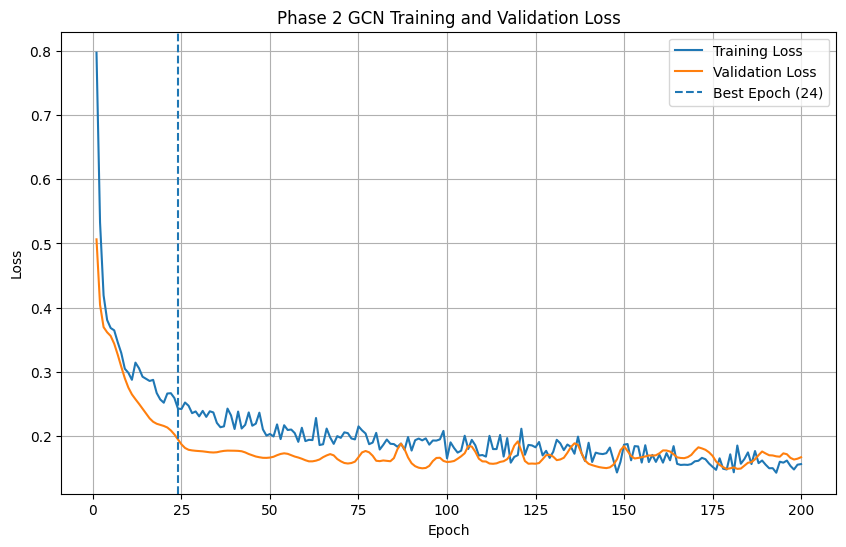

In [120]:
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    train_losses,
    label="Training Loss"
)

plt.plot(
    epochs_range,
    val_losses,
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Phase 2 GCN Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

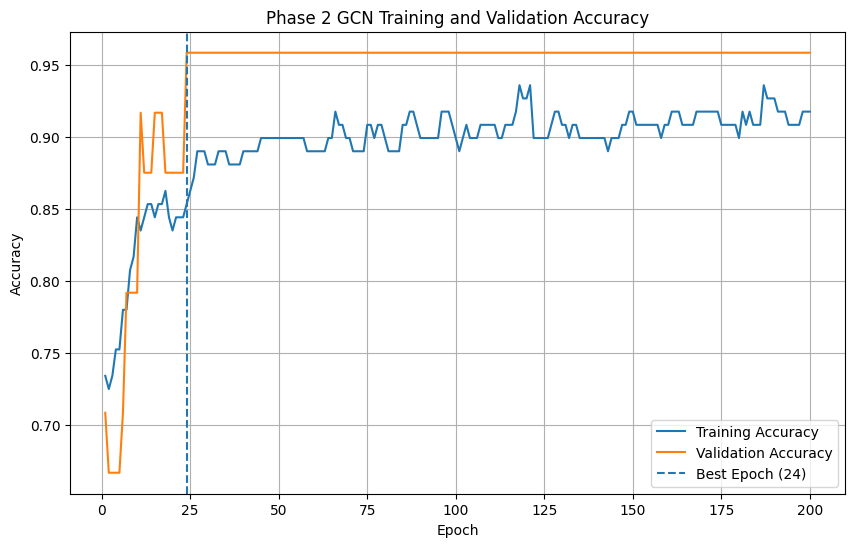

In [121]:
plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    val_accuracies,
    label="Validation Accuracy"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Phase 2 GCN Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

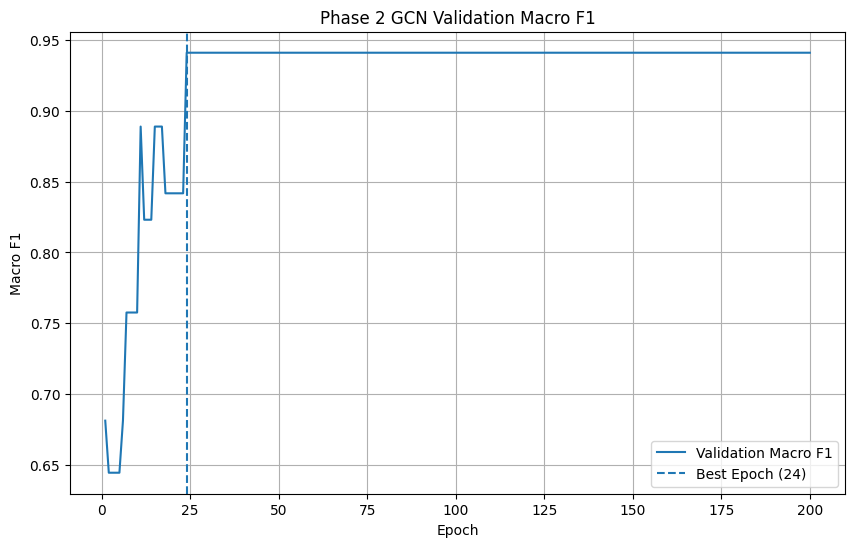

In [122]:
plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    val_f1_scores,
    label="Validation Macro F1"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("Phase 2 GCN Validation Macro F1")

plt.legend()
plt.grid(True)
plt.show()

In [123]:
# ============================================
# STEP 10: Final Test Evaluation
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model_phase2.eval()

with torch.no_grad():

    output = model_phase2(
        graph_data_phase2.x.to(device),
        graph_data_phase2.edge_index.to(device),
        graph_data_phase2.edge_weight.to(device)
    )

    test_output = output[
        graph_data_phase2.test_mask
    ]

    test_true = graph_data_phase2.y[
        graph_data_phase2.test_mask
    ].to(device)

    test_pred = test_output.argmax(dim=1)

# Convert to NumPy
y_test_true = test_true.cpu().numpy()
y_test_pred = test_pred.cpu().numpy()

print("Number of test nodes:", len(y_test_true))
print("Test predictions generated successfully.")

Number of test nodes: 24
Test predictions generated successfully.


In [124]:
# ============================================
# Calculate Test Metrics
# ============================================

test_accuracy = accuracy_score(
    y_test_true,
    y_test_pred
)

test_precision = precision_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="weighted",
    zero_division=0
)

print("============================================")
print("PHASE 2 GCN - FINAL TEST RESULTS")
print("============================================")

print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Macro Precision:   {test_precision:.4f}")
print(f"Macro Recall:      {test_recall:.4f}")
print(f"Macro F1:          {test_macro_f1:.4f}")
print(f"Weighted F1:       {test_weighted_f1:.4f}")

PHASE 2 GCN - FINAL TEST RESULTS
Accuracy:          0.8750
Macro Precision:   0.8125
Macro Recall:      0.9211
Macro F1:          0.8418
Weighted F1:       0.8841


In [125]:
# ============================================
# Classification Report
# ============================================

target_names = [
    "Low Risk",
    "High Risk"
]

print(
    classification_report(
        y_test_true,
        y_test_pred,
        target_names=target_names,
        zero_division=0,
        digits=4
    )
)

              precision    recall  f1-score   support

    Low Risk     1.0000    0.8421    0.9143        19
   High Risk     0.6250    1.0000    0.7692         5

    accuracy                         0.8750        24
   macro avg     0.8125    0.9211    0.8418        24
weighted avg     0.9219    0.8750    0.8841        24



In [126]:
# ============================================
# Confusion Matrix
# ============================================

cm = confusion_matrix(
    y_test_true,
    y_test_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[16  3]
 [ 0  5]]


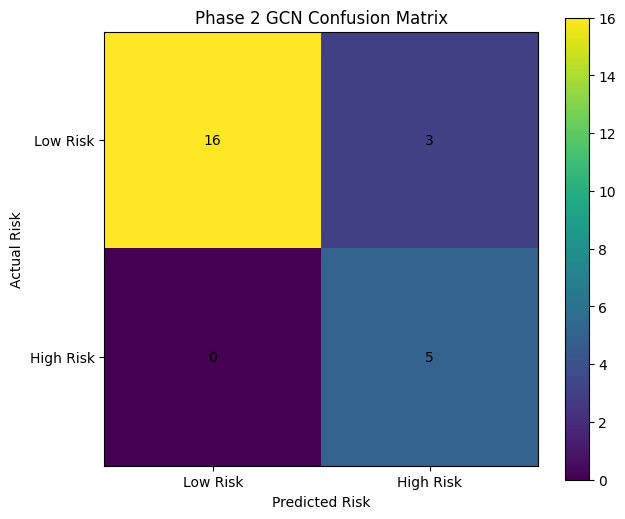

In [127]:
plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.title("Phase 2 GCN Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")

plt.xticks(
    [0, 1],
    ["Low Risk", "High Risk"]
)

plt.yticks(
    [0, 1],
    ["Low Risk", "High Risk"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

In [128]:
# ============================================
# Save Phase 2 Results
# ============================================

phase2_results = pd.DataFrame({
    "Model": ["GCN"],
    "Accuracy": [test_accuracy],
    "Macro_Precision": [test_precision],
    "Macro_Recall": [test_recall],
    "Macro_F1": [test_macro_f1],
    "Weighted_F1": [test_weighted_f1],
    "Best_Epoch": [best_epoch],
    "Best_Validation_Macro_F1": [best_val_f1]
})

phase2_results

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Best_Epoch,Best_Validation_Macro_F1
0,GCN,0.875,0.8125,0.921053,0.841758,0.884066,24,0.941032


In [129]:
import os

os.makedirs("models", exist_ok=True)

print("Models directory ready.")

Models directory ready.


In [130]:
# ============================================
# Save Best Phase 2 GCN
# ============================================

phase2_model_path = "models/phase2_victimisation_gcn.pth"

torch.save(
    {
        "model_state_dict": best_model_state,
        "input_features": input_features,
        "hidden_features": hidden_features,
        "output_classes": output_classes,
        "dropout": dropout,
        "best_epoch": best_epoch,
        "best_validation_macro_f1": best_val_f1,
        "feature_columns": phase2_feature_columns
    },
    phase2_model_path
)

print("Phase 2 model saved successfully:")
print(phase2_model_path)

Phase 2 model saved successfully:
models/phase2_victimisation_gcn.pth


In [131]:
import joblib

scaler_path = "models/phase2_scaler.pkl"

joblib.dump(
    scaler_phase2,
    scaler_path
)

print("Scaler saved successfully:")
print(scaler_path)

Scaler saved successfully:
models/phase2_scaler.pkl


In [132]:
phase2_label_info = {
    0: "Low Victimisation Risk",
    1: "High Victimisation Risk"
}

import json

with open(
    "models/phase2_label_info.json",
    "w"
) as f:
    json.dump(
        phase2_label_info,
        f,
        indent=4
    )

print("Label information saved.")

Label information saved.


In [133]:
print("========== SAVED MODEL FILES ==========")

for filename in os.listdir("models"):
    print(filename)

========== SAVED MODEL FILES ==========
phase2_label_info.json
phase2_scaler.pkl
phase2_victimisation_gcn.pth
